In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
#from xgboost import XGBClassifier
#from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score, log_loss
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalMaxPooling1D, Flatten
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Input, Dropout, Flatten
from tensorflow.keras.layers import Attention, Concatenate
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight
#from imblearn.over_sampling import SMOTE

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#audio_df = pd.read_csv("/content/drive/MyDrive/datasets/DAICWOZ/complete_audio_woOutliers.csv")
audio_df = pd.read_csv("/content/drive/MyDrive/datasets/DAICWOZ/matchingrows/complete_audio_clean_matchingrows.csv")

In [ ]:
display(audio_df)

,F0,F1,F2,F3,F4,0,2,3,4,5,...,65,66,67,68,69,70,71,72,73,Target
0,293.20,1635.5,2538.1,3242.0,3988.0,269.0,0.038446,0.111760,0.9758,0.22440,...,-0.92749,-0.74712,-0.54045,-0.42579,-0.40818,-0.27205,-0.18758,-0.115740,-0.079553,0
1,318.92,1656.0,2726.0,3413.0,4225.6,269.0,0.025810,0.080351,0.0000,0.34022,...,-0.93171,-0.74674,-0.55854,-0.43645,-0.41822,-0.27231,-0.18013,-0.141710,-0.093744,0
2,582.25,1469.5,2423.0,3034.3,4043.2,271.0,0.045581,0.179910,-5.3092,0.47652,...,-0.98807,-0.77188,-0.59350,-0.41623,-0.29127,-0.19868,-0.11678,-0.124110,-0.113760,0
3,476.97,2103.9,3067.2,4082.9,4639.4,231.0,0.058752,0.170800,-4.2914,0.26402,...,-0.66118,-0.66544,-0.68464,-0.62956,-0.61106,-0.35705,-0.26494,-0.145970,-0.166570,0
4,507.50,1305.0,1740.2,2812.2,3542.5,182.0,0.082644,0.237140,-4.6301,0.67685,...,-0.70488,-0.71061,-0.69635,-0.60842,-0.58210,-0.39583,-0.28554,-0.204080,-0.150490,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
568340,222.24,1945.2,2819.0,4040.8,4784.6,152.0,0.201670,0.548830,9.2067,0.35271,...,-0.88044,-0.56210,-0.64258,-0.57587,-0.43868,-0.30497,-0.28417,-0.144310,-0.051550,0
568341,581.16,1820.0,2496.1,3225.3,4017.1,209.0,0.034666,0.349750,5.6566,0.12914,...,-0.84567,-0.73813,-0.63178,-0.54548,-0.51871,-0.30890,-0.27262,-0.134150,-0.067753,0
568342,523.00,1251.3,2007.7,2864.9,3914.0,207.5,0.134000,0.386820,-5.1442,0.19695,...,-0.83250,-0.73273,-0.62752,-0.53681,-0.51673,-0.27603,-0.26620,-0.111950,-0.042231,0
568343,523.00,852.0,1765.2,2886.5,4060.9,206.0,0.162830,0.502370,10.1350,0.21850,...,-0.86057,-0.74837,-0.61421,-0.49968,-0.47533,-0.19490,-0.19090,-0.020043,0.059151,0


In [ ]:
audio_df["Target"].value_counts()

,count
Target,
0,397624
1,170721


In [ ]:
X = audio_df.drop(columns=["Target"]).values
y = audio_df["Target"].values

In [ ]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
# Reshape for BiLSTM
sequence_length = 6
num_features = X_scaled.shape[1] // sequence_length
X_reshaped = X_scaled.reshape(-1, sequence_length, num_features)

In [ ]:
# train-test split
X_train, X_test, y_train, y_test = train_test_split(X_reshaped, y, test_size=0.2, random_state=42, stratify=y)

# Evaluation

In [ ]:
# Evaluate Models
def evaluate_model(y_true, y_pred, model_name):
    print(f"Evaluation for {model_name}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("Classification Report:")
    print(classification_report(y_true, y_pred))
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall:", recall_score(y_true, y_pred))
    print("F1 Score:", f1_score(y_true, y_pred))
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp)
    print("Specificity:", specificity)
    print("ROC-AUC:", roc_auc_score(y_true, y_pred))

In [ ]:
# Plot Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix for {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [ ]:
# Plotting the training and validation accuracy and loss
def plot_training_history(history, model_name):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))
    #plt.rcParams.update({"font.size": 16})
    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"])
    plt.plot(history.history["val_accuracy"])
    plt.title(f"Model Accuracy for {model_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend(["Training", "Validation"], loc="lower right")

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"])
    plt.plot(history.history["val_loss"])
    plt.title(f"Model Loss for {model_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend(["Training", "Validation"], loc="upper right")

    plt.tight_layout()
    plt.show()

In [ ]:
# Plot Precision-Recall Curve
def plot_roc_recall(model, X_test, y_test, model_name):
    # Plot ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, model.predict(X_test))
    plt.plot(fpr, tpr, color="blue", lw=2, label="ROC curve")
    plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve for {model_name}")
    plt.legend(loc="lower right")
    plt.show()

    # Plot precision-recall curve
    precision, recall, thresholds = precision_recall_curve(y_test, model.predict(X_test))
    plt.plot(recall, precision, color="blue", lw=2, label="Precision-Recall curve")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision-Recall Curve for {model_name}")
    plt.legend(loc="lower left")
    plt.show()

# BiLSTM + Attention

In [ ]:
# Build BiLSTM with Attention model
def build_bilstm_attention_model(input_shape):
    input_layer = Input(shape=input_shape)
    bilstm = Bidirectional(LSTM(64, return_sequences=True))(input_layer)

    attention = Attention()([bilstm, bilstm])
    combined = Concatenate()([bilstm, attention])
    pooling = GlobalMaxPooling1D()(combined)

    # dense layers
    dense = Dense(64, activation="relu")(pooling)
    dropout = Dropout(0.5)(dense)
    output_layer = Dense(1, activation="sigmoid")(dropout)

    model = Model(inputs=input_layer, outputs=output_layer)
    return model

In [ ]:
# Build and compile the model
model = build_bilstm_attention_model((sequence_length, num_features))
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [ ]:
# Train the model
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test))

In [ ]:
# Predict
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

4240/4240 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step


In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred)


conf_matrix = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = conf_matrix.ravel()
specificity = tn / (tn + fp)


print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Specificity: {specificity:.4f}")

Accuracy: 0.8768
Precision: 0.8410
Recall: 0.7203
F1 Score: 0.7760
ROC-AUC: 0.8315
Specificity: 0.9426


In [ ]:
confusion_matrix(y_test, y_pred)

array([[90000,  5476],
       [11244, 28958]])

In [ ]:
evaluate_model(y_test, y_pred, "BiLSTM + Attention")

Evaluation for BiLSTM + Attention
Confusion Matrix:
[[90000  5476]
 [11244 28958]]
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.94      0.92     95476
           1       0.84      0.72      0.78     40202

    accuracy                           0.88    135678
   macro avg       0.86      0.83      0.85    135678
weighted avg       0.87      0.88      0.87    135678

Accuracy: 0.8767670514011114
Precision: 0.8409711331823198
Recall: 0.7203124222675489
F1 Score: 0.7759794201189774
Specificity: 0.9426452721102685
ROC-AUC: 0.8314788471889086


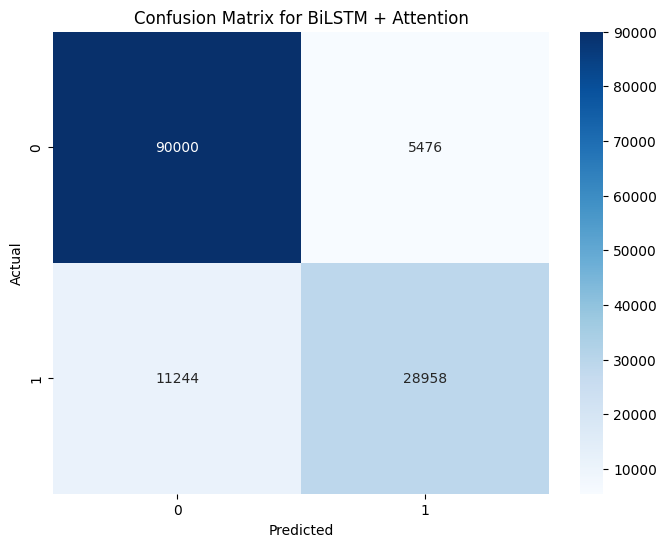

In [ ]:
plot_confusion_matrix(y_test, y_pred, "BiLSTM + Attention")

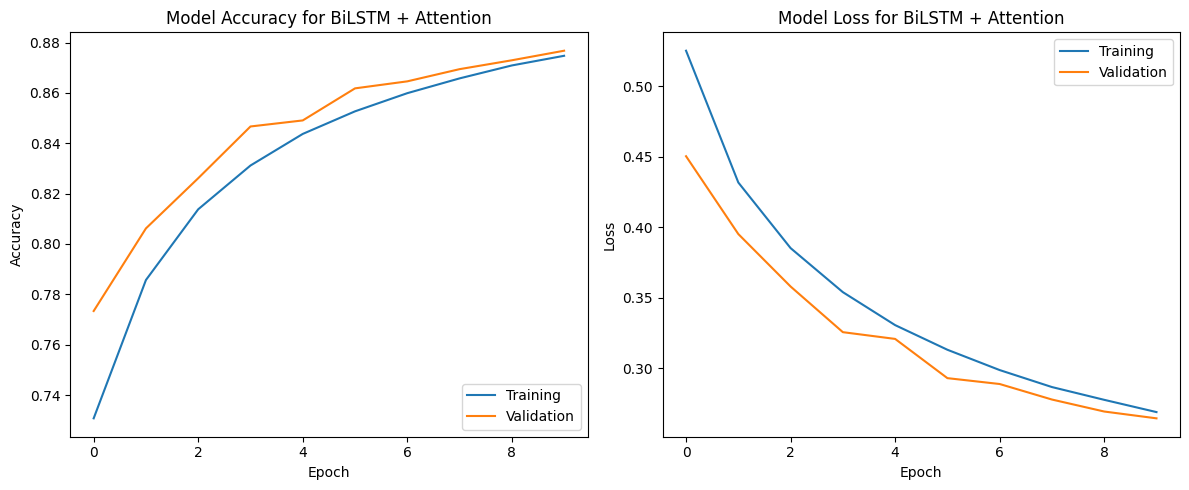

In [ ]:
plot_training_history(history, "BiLSTM + Attention")

4240/4240 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step


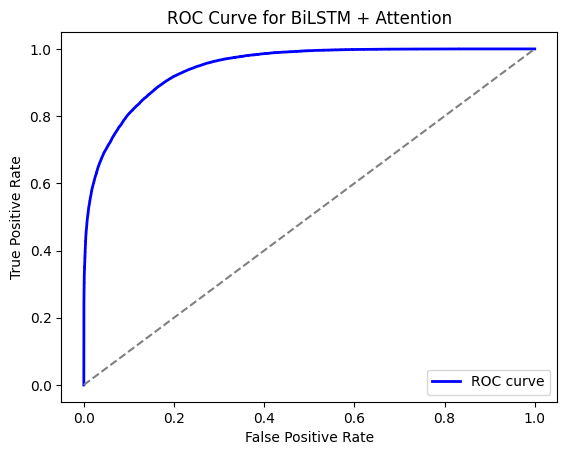

4240/4240 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step


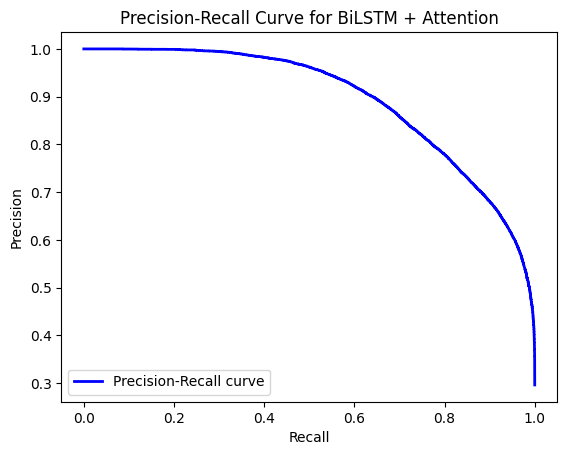

In [ ]:
plot_roc_recall(model, X_test, y_test, "BiLSTM + Attention")